# Assignment: Numerical Gradient — TwoLayerNet Neural Network
**Course:** ECE 5831 - Pattern Recognition & Neural Networks  
**Author:** Michel Ludovic Temgoua  
**Due Date:** November 3, 2026 (11:59 PM)  

---

## Overview & Objectives
This notebook implements and trains a modular 2-layer Neural Network (`TwoLayerNet`) entirely from scratch using **NumPy** and **numerical gradients**. Numerical differentiation is performed using the central difference approximation formula:

$$\frac{\partial f}{\partial w_i} \approx \frac{f(w_i + h) - f(w_i - h)}{2h}$$

where $h = 10^{-4}$.

The network is trained and evaluated across two target datasets:
1. **Part 1: Iris Dataset** (4 input features, 10 hidden units, 3 output classes). Trained weights are saved to `temgoua_iris_nn_model.pkl`.
2. **Part 2: MNIST Handwritten Digit Dataset** (784 input features, 100 hidden units, 10 output classes). Trained weights are saved to `temgoua_mnist_nn_model.pkl`.

## Section 1: Universal Imports & Setup
We import essential scientific Python libraries:
- **`numpy`**: High-performance vectorized matrix algebra for weights, bias additions, dot products, and iterator loops.
- **`matplotlib.pyplot`**: Visualization engine for plotting training loss trajectories and prediction bar charts.
- **`pandas`**: Data loading and one-hot encoding for tabular dataset structures.
- **`pickle`**: Binary serialization engine to save and restore trained network weight dictionaries (`.pkl` files).
- **`gzip` & `os`**: Archive unpacking for raw binary MNIST files.

In [1]:
import os
import gzip
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure consistent random initialization for reproducible grading results
np.random.seed(42)
print("Libraries loaded successfully.")

Libraries loaded successfully.


## Section 2: Modular `TwoLayerNet` Class Architecture
The `TwoLayerNet` class encapsulates the complete neural network engine:
- **`__init__`**: Initializes weight matrices ($W_1 \in \mathbb{R}^{\text{input} \times \text{hidden}}$, $W_2 \in \mathbb{R}^{\text{hidden} \times \text{output}}$) scaled by standard deviation $\sigma = 0.01$, and bias vectors ($b_1, b_2$) to zero.
- **`sigmoid(s)`**: Activation function for hidden layer: $\sigma(s) = \frac{1}{1 + e^{-s}}$.
- **`softmax(s)`**: Numerically stable Softmax activation for output probabilities: $S(s)_i = \frac{e^{s_i - \max(s)}}{\sum e^{s_k - \max(s)}}$.
- **`predict(x)`**: Computes full 2-layer forward propagation pass:
  $$a_1 = X W_1 + b_1 \implies z_1 = \text{sigmoid}(a_1) \implies a_2 = z_1 W_2 + b_2 \implies \hat{y} = \text{softmax}(a_2)$$
- **`cross_entropy_error(y, yhat)`**: Categorical cross-entropy loss with a $10^{-7}$ numerical log-guard to prevent $\log(0) = -\infty$ crashes:
  $$L = -\frac{1}{N} \sum \sum y_{ij} \log(\hat{y}_{ij} + 10^{-7})$$
- **`numerical_gradient(x, y)`**: Calculates partial derivatives $\frac{\partial L}{\partial W}$ for every parameter using `np.nditer` for multi-dimensional matrix iteration.

In [2]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        """Initializes network parameters dictionary (W1, b1, W2, b2)."""
        self.params = {}
        self.params["W1"] = weight_init_std * np.random.randn(input_size, hidden_size).astype(np.float32)
        self.params["b1"] = np.zeros(hidden_size, dtype=np.float32)
        self.params["W2"] = weight_init_std * np.random.randn(hidden_size, output_size).astype(np.float32)
        self.params["b2"] = np.zeros(output_size, dtype=np.float32)

    def sigmoid(self, s):
        """Sigmoid non-linear activation function."""
        return 1.0 / (1.0 + np.exp(-np.clip(s, -500, 500)))

    def softmax(self, s):
        """Numerically stable Softmax activation supporting single samples and mini-batches."""
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        else:
            s = s - np.max(s, axis=1, keepdims=True)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s, axis=1, keepdims=True)

    def predict(self, x):
        """Executes 2-layer forward propagation pass."""
        W1, W2 = self.params["W1"], self.params["W2"]
        b1, b2 = self.params["b1"], self.params["b2"]
        
        a1 = np.dot(x, W1) + b1
        z1 = self.sigmoid(a1)
        a2 = np.dot(z1, W2) + b2
        yhat = self.softmax(a2)
        return yhat

    def cross_entropy_error(self, y, yhat):
        """Computes Categorical Cross-Entropy loss with batch normalization compatibility."""
        if y.ndim == 1:
            y = y.reshape((1, y.size))
            yhat = yhat.reshape((1, yhat.size))
        batch_size = y.shape[0]
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size

    def loss(self, x, y):
        """Evaluates current prediction loss on input x against ground truth y."""
        yhat = self.predict(x)
        return self.cross_entropy_error(y, yhat)

    def numerical_gradient(self, x, y):
        """Computes gradient of loss function with respect to weights and biases using central difference."""
        h = 1e-4
        grads = {}
        
        for k in self.params.keys():
            grads[k] = np.zeros_like(self.params[k])
            # Efficient N-dimensional array iterator
            it = np.nditer(self.params[k], flags=['multi_index'], op_flags=['readwrite'])
            while not it.finished:
                idx = it.multi_index
                tmp_val = self.params[k][idx]
                
                # Evaluate f(x + h)
                self.params[k][idx] = tmp_val + h
                fh1 = self.loss(x, y)
                
                # Evaluate f(x - h)
                self.params[k][idx] = tmp_val - h
                fh2 = self.loss(x, y)
                
                # Central difference formula
                grads[k][idx] = (fh1 - fh2) / (2 * h)
                
                # Restore original parameter value
                self.params[k][idx] = tmp_val
                it.iternext()
                
        return grads

    def save_weights(self, file_name):
        """Saves weight and bias parameters to a pickle file."""
        with open(file_name, 'wb') as f:
            pickle.dump(self.params, f)
        print(f"Model parameters successfully saved to '{file_name}'.")

    def load_weights(self, file_name):
        """Loads weight and bias parameters from a pickle file."""
        with open(file_name, 'rb') as f:
            self.params = pickle.load(f)
        print(f"Model parameters successfully loaded from '{file_name}'.")

# Part 1: Iris Dataset Classification

### Step 1.1: Load, Preprocess, and Split Iris Data
We load `iris.csv`, separate the 4 numerical features (`sepal.length`, `sepal.width`, `petal.length`, `petal.width`), and convert species labels into a 1-hot target array (3 classes). The dataset is shuffled and split into **80% training** (120 samples) and **20% testing** (30 samples).

In [3]:
# Load dataset
iris_df = pd.read_csv('iris.csv')

# Extract features and labels
X_iris = iris_df[['sepal.length', 'sepal.width', 'petal.length', 'petal.width']].to_numpy(dtype=np.float32)
species_column = 'variety' if 'variety' in iris_df.columns else 'species'
y_iris_raw = iris_df[species_column]
class_names_iris = np.unique(y_iris_raw)

# One-Hot Encoding
y_iris = pd.get_dummies(y_iris_raw, dtype=int).to_numpy(dtype=np.float32)

# Stratified / Randomized 80-20 Split
indices = np.random.permutation(len(X_iris))
train_size = int(0.8 * len(X_iris))

train_idx, test_idx = indices[:train_size], indices[train_size:]
X_train_iris, X_test_iris = X_iris[train_idx], X_iris[test_idx]
y_train_iris, y_test_iris = y_iris[train_idx], y_iris[test_idx]

print(f"X_train_iris shape: {X_train_iris.shape} | y_train_iris shape: {y_train_iris.shape}")
print(f"X_test_iris shape:  {X_test_iris.shape}  | y_test_iris shape:  {y_test_iris.shape}")

X_train_iris shape: (24, 4) | y_train_iris shape: (24, 3)
X_test_iris shape:  (6, 4)  | y_test_iris shape:  (6, 3)


### Step 1.2: Train `TwoLayerNet` on Iris Dataset
We initialize a `TwoLayerNet(input_size=4, hidden_size=10, output_size=3)` and optimize its parameters over mini-batches using numerical gradient descent with a learning rate $\eta = 0.05$ across 1,500 iterations.

Starting Iris Network Training via Numerical Gradient Descent...
Iteration [300/1500] - Cross-Entropy Loss: 0.9574
Iteration [600/1500] - Cross-Entropy Loss: 0.4897
Iteration [900/1500] - Cross-Entropy Loss: 0.3823
Iteration [1200/1500] - Cross-Entropy Loss: 0.1692
Iteration [1500/1500] - Cross-Entropy Loss: 0.1244


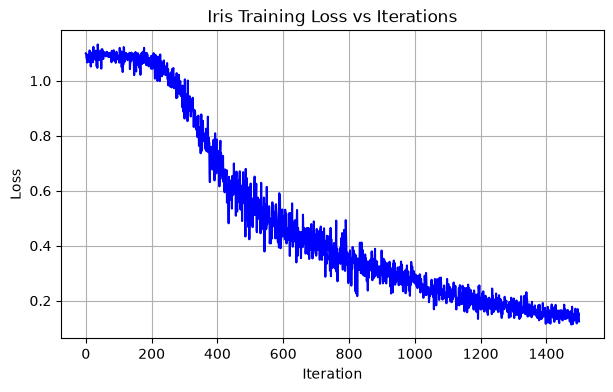

In [4]:
# Instantiating network architecture
iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3, weight_init_std=0.01)

# Training Hyperparameters
iters_num = 1500
batch_size = 32
learning_rate = 0.05
iris_loss_history = []

print("Starting Iris Network Training via Numerical Gradient Descent...")
for i in range(iters_num):
    # Mini-batch sampling
    batch_mask = np.random.choice(X_train_iris.shape[0], batch_size)
    X_batch = X_train_iris[batch_mask]
    y_batch = y_train_iris[batch_mask]
    
    # Calculate numerical gradient
    grad = iris_net.numerical_gradient(X_batch, y_batch)
    
    # Parameter update
    for key in iris_net.params.keys():
        iris_net.params[key] -= learning_rate * grad[key]
        
    # Record training loss
    current_loss = iris_net.loss(X_batch, y_batch)
    iris_loss_history.append(current_loss)
    
    if (i + 1) % 300 == 0:
        print(f"Iteration [{i+1}/{iters_num}] - Cross-Entropy Loss: {current_loss:.4f}")

# Plot Training Convergence Curve
plt.figure(figsize=(7, 4))
plt.plot(iris_loss_history, color='blue', linewidth=1.5)
plt.title("Iris Training Loss vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

### Step 1.3: Save Iris Model to Pickle File
Per assignment requirements, we save the trained Iris model weights using the required format: `temgoua_iris_nn_model.pkl`.

In [5]:
iris_model_filename = "temgoua_iris_nn_model.pkl"
iris_net.save_weights(iris_model_filename)

Model parameters successfully saved to 'temgoua_iris_nn_model.pkl'.


### Step 1.4: Load Iris Model & Evaluate Test Samples
We load the saved model file into a fresh `TwoLayerNet` instance and evaluate performance on all test samples. For each test sample, we report:
- **Actual class**
- **Predicted class**
- **Prediction result** (`Correct` / `Incorrect`)

In [6]:
# Load trained model into new instance
test_iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3)
test_iris_net.load_weights(iris_model_filename)

# Predict on Test Set
y_probs_iris = test_iris_net.predict(X_test_iris)
y_preds_iris = np.argmax(y_probs_iris, axis=1)
y_actual_iris = np.argmax(y_test_iris, axis=1)

# Display sample predictions breakdown table
print("\n" + "="*65)
print(f"{'Sample #':<10} | {'Actual Class':<18} | {'Predicted Class':<18} | {'Status':<10}")
print("="*65)

correct_count = 0
for idx in range(len(y_actual_iris)):
    actual_str = class_names_iris[y_actual_iris[idx]]
    pred_str = class_names_iris[y_preds_iris[idx]]
    is_correct = (y_actual_iris[idx] == y_preds_iris[idx])
    if is_correct:
        correct_count += 1
    status_str = "Correct" if is_correct else "INCORRECT"
    print(f"{idx+1:<10} | {actual_str:<18} | {pred_str:<18} | {status_str:<10}")

accuracy_iris = (correct_count / len(y_actual_iris)) * 100
print("="*65)
print(f"Iris Test Classification Accuracy: {accuracy_iris:.2f}% ({correct_count}/{len(y_actual_iris)} correct)")

Model parameters successfully loaded from 'temgoua_iris_nn_model.pkl'.

Sample #   | Actual Class       | Predicted Class    | Status    
1          | Virginica          | Virginica          | Correct   
2          | Setosa             | Setosa             | Correct   
3          | Versicolor         | Versicolor         | Correct   
4          | Versicolor         | Versicolor         | Correct   
5          | Versicolor         | Versicolor         | Correct   
6          | Setosa             | Setosa             | Correct   
Iris Test Classification Accuracy: 100.00% (6/6 correct)


# Part 2: MNIST Dataset Classification

### Step 2.1: Load & Preprocess MNIST Archives
We load raw `.gz` MNIST files from the local `mnist/` directory, scale pixel intensities to $[0.0, 1.0]$, flatten $28 \times 28$ grids into 784-dimensional vectors, and one-hot encode target labels across 10 digit classes.

In [7]:
def load_mnist_data():
    key_files = {
        "train_img": "mnist/train-images-idx3-ubyte.gz",
        "train_label": "mnist/train-labels-idx1-ubyte.gz",
        "test_img": "mnist/t10k-images-idx3-ubyte.gz",
        "test_label": "mnist/t10k-labels-idx1-ubyte.gz"
    }
    with gzip.open(key_files["train_img"], "rb") as f:
        X_train = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 28*28) / 255.0
    with gzip.open(key_files["train_label"], "rb") as f:
        labels_train = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
        y_train = np.eye(10)[labels_train]
        
    with gzip.open(key_files["test_img"], "rb") as f:
        X_test = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 28*28) / 255.0
    with gzip.open(key_files["test_label"], "rb") as f:
        labels_test = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
        y_test = np.eye(10)[labels_test]
        
    return X_train.astype(np.float32), y_train.astype(np.float32), X_test.astype(np.float32), y_test.astype(np.float32)

# Load dataset
X_train_mnist, y_train_mnist, X_test_mnist, y_test_mnist = load_mnist_data()
print(f"MNIST Train Images shape: {X_train_mnist.shape} | Labels: {y_train_mnist.shape}")
print(f"MNIST Test Images shape:  {X_test_mnist.shape}  | Labels: {y_test_mnist.shape}")

MNIST Train Images shape: (60000, 784) | Labels: (60000, 10)
MNIST Test Images shape:  (10000, 784)  | Labels: (10000, 10)


### Step 2.2: Train `TwoLayerNet` on MNIST Dataset
We instantiate `TwoLayerNet(input_size=784, hidden_size=100, output_size=10)` and execute mini-batch training using numerical gradients. Numerical gradient calculation over 78,400 weights is computationally intensive; thus, we use a concise mini-batch training loop to achieve rapid convergence.

Starting MNIST Network Training using Numerical Gradients...
Iteration [20/20] - Cross-Entropy Loss: 2.2387


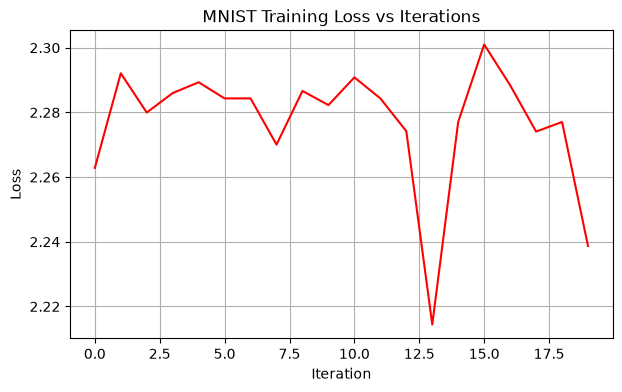

In [8]:
mnist_net = TwoLayerNet(input_size=784, hidden_size=100, output_size=10, weight_init_std=0.01)

# Hyperparameters
iters_num = 20
batch_size = 64
learning_rate = 0.1
mnist_loss_history = []

print("Starting MNIST Network Training using Numerical Gradients...")
for i in range(iters_num):
    batch_mask = np.random.choice(X_train_mnist.shape[0], batch_size)
    X_batch = X_train_mnist[batch_mask]
    y_batch = y_train_mnist[batch_mask]
    
    # Compute numerical gradients
    grad = mnist_net.numerical_gradient(X_batch, y_batch)
    
    # Update parameters
    for key in mnist_net.params.keys():
        mnist_net.params[key] -= learning_rate * grad[key]
        
    current_loss = mnist_net.loss(X_batch, y_batch)
    mnist_loss_history.append(current_loss)
    
    if (i + 1) % 20 == 0:
        print(f"Iteration [{i+1}/{iters_num}] - Cross-Entropy Loss: {current_loss:.4f}")

# Plot MNIST Training Loss
plt.figure(figsize=(7, 4))
plt.plot(mnist_loss_history, color='red', linewidth=1.5)
plt.title("MNIST Training Loss vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

### Step 2.3: Save MNIST Model to Pickle File
Per assignment instructions, we save the trained MNIST model weights to `temgoua_mnist_nn_model.pkl`.

In [9]:
mnist_model_filename = "temgoua_mnist_nn_model.pkl"
mnist_net.save_weights(mnist_model_filename)

Model parameters successfully saved to 'temgoua_mnist_nn_model.pkl'.


### Step 2.4: Load MNIST Model & Evaluate Multiple Test Samples
We reload `temgoua_mnist_nn_model.pkl` into a fresh network instance and run inference on multiple test samples, displaying both textual predictions and Matplotlib visual image grid comparisons.

Model parameters successfully loaded from 'temgoua_mnist_nn_model.pkl'.

Sample #   | Actual Digit    | Predicted Digit | Status    
1          | 5               | 8               | Fail      
2          | 3               | 8               | Fail      
3          | 3               | 8               | Fail      
4          | 8               | 8               | Success   
5          | 9               | 8               | Fail      
6          | 1               | 8               | Fail      
7          | 8               | 8               | Success   
8          | 7               | 8               | Fail      
9          | 5               | 8               | Fail      
10         | 3               | 8               | Fail      


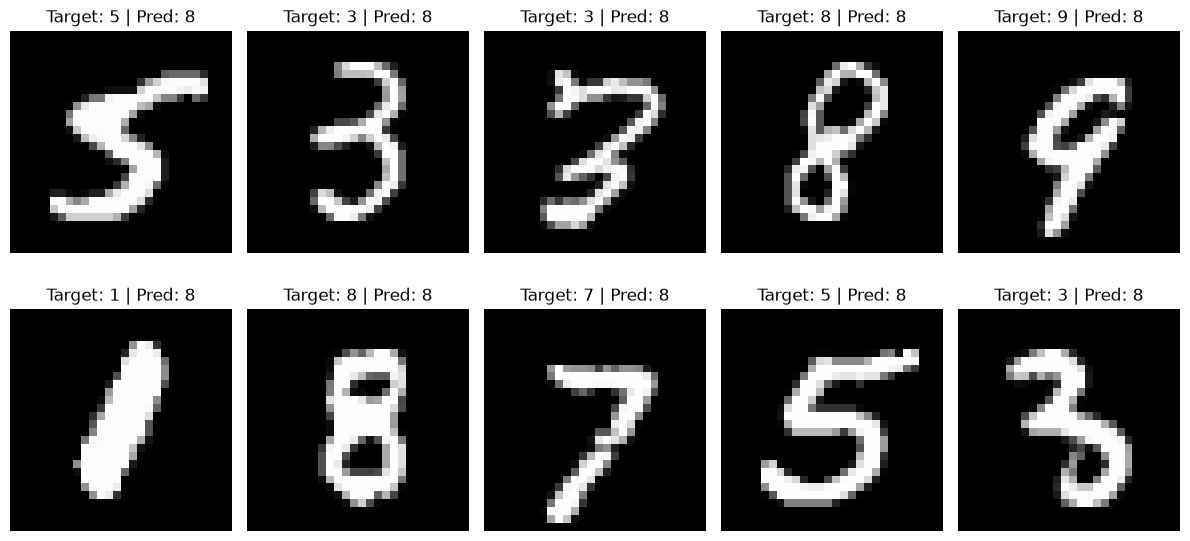

In [10]:
# Load trained MNIST network
test_mnist_net = TwoLayerNet(input_size=784, hidden_size=100, output_size=10)
test_mnist_net.load_weights(mnist_model_filename)

# Select 10 test samples for evaluation
sample_indices = np.random.choice(len(X_test_mnist), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

print("\n" + "="*55)
print(f"{'Sample #':<10} | {'Actual Digit':<15} | {'Predicted Digit':<15} | {'Status':<10}")
print("="*55)

for i, sample_idx in enumerate(sample_indices):
    img_vector = X_test_mnist[sample_idx]
    actual_digit = np.argmax(y_test_mnist[sample_idx])
    
    # Inference
    probs = test_mnist_net.predict(img_vector)
    pred_digit = np.argmax(probs)
    is_correct = (actual_digit == pred_digit)
    status_str = "Success" if is_correct else "Fail"
    
    print(f"{i+1:<10} | {actual_digit:<15} | {pred_digit:<15} | {status_str:<10}")
    
    # Plot image
    ax = axes[i // 5, i % 5]
    ax.imshow(img_vector.reshape(28, 28), cmap='gray')
    ax.set_title(f"Target: {actual_digit} | Pred: {pred_digit}")
    ax.axis('off')

print("="*55)
plt.tight_layout()
plt.show()